# 02 — Burst morphologies, SNR and injections

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What this notebook does**

1. Defines the three burst morphologies of the project (sine-Gaussian, Gaussian pulse, linear chirp) through their
   **exact analytic Fourier transforms**, and checks them against a brute-force numerical transform.
2. Defines the **optimal SNR** $\rho^2=4\int|\tilde h|^2/S_n\,df$ with the PSD of each chunk and compares it with the
   time-domain proxy used in the exploratory notebook `00`.
3. Validates the injection chain on real noise: the matched-filter output on injected data must follow a non-central
   $\chi^2_2(\rho^2)$ law.
4. Shows how bursts of increasing SNR look in the whitened time series and in the time–frequency plane.

**What it does not do**: no detection statistic, no threshold, no inference (notebooks 03–05).

Unlike notebook `00`, signals are **not** added in the time domain after whitening: they are built directly as whitened
frequency bins $V_k = 2\tilde h(f_k)/\sqrt{S_n(f_k)}$ and added to the real whitened noise bins. This is equivalent
(whitening is linear) and gives the exact SNR, with the correct PSD, with no filter transients.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, signal
import gwosc_tools as g
g.style()
rng = np.random.default_rng(7)
test = g.load_chunk(3)
noise, S1 = test["v"], test["S1"]
print("test chunk 3:", noise.shape)

test chunk 3: (4056, 1024)


## 1. The three morphologies

| Morphology | $h(t)$ | parameters | injection prior |
|---|---|---|---|
| sine-Gaussian (SG) | $e^{-t^2/2\sigma^2}\cos(2\pi f_0t+\phi)$, $\sigma=Q/2\pi f_0$ | $t_0,f_0,Q,\phi$ | $f_0\sim$ log-U(50,400) Hz, $Q\sim$ U(4,15) |
| Gaussian pulse | $e^{-t^2/2\sigma^2}$ | $t_0,\sigma$ | $\sigma\sim$ log-U(0.8,5) ms |
| linear chirp | $e^{-t^2/2\sigma^2}\sin(2\pi f_0 t+\pi\dot f t^2+\phi)$ | $t_0,f_0,\dot f,\sigma$ | $f_0\sim$ U(50,150), $\dot f\sim$ U(150,600) Hz/s, $\sigma\sim$ U(30,80) ms |

$t_0\sim$ U(0.25, 0.75) s inside the 1 s window and $\phi\sim$ U(0, 2π) for all. The Fourier transforms are closed-form
(Gaussian integrals with complex width), implemented in `gwosc_tools.py`. Check against a numerical FFT:

In [2]:
fs_fine = 16384
t = (np.arange(fs_fine) - fs_fine // 2) / fs_fine           # 1 s centred at 0
f = g.FREQ

def numeric_ft(h):
    return np.fft.rfft(np.fft.ifftshift(h)) / fs_fine      # continuous FT sampled at 1 Hz (T = 1 s)

cases = {
    "sg":    (lambda: (np.exp(-t**2 / (2 * (8 / (2*np.pi*150))**2)) * np.cos(2*np.pi*150*t + 0.7)),
              lambda: g.sine_gaussian_ft(f, 150., 8., 0.7)),
    "pulse": (lambda: np.exp(-t**2 / (2 * 0.003**2)),
              lambda: g.gaussian_pulse_ft(f, 0.003) + 0j),
    "chirp": (lambda: np.exp(-t**2 / (2 * 0.05**2)) * np.sin(2*np.pi*80*t + np.pi*300*t**2 + 0.3),
              lambda: g.chirp_ft(f, 80., 300., 0.05, 0.3)),
}
for k, (num, ana) in cases.items():
    a, b = numeric_ft(num())[:513], ana()
    print(f"{k:6s} max |analytic - numeric| / max|h| = {np.max(np.abs(a - b)) / np.max(np.abs(b)):.2e}")

sg     max |analytic - numeric| / max|h| = 5.77e-16
pulse  max |analytic - numeric| / max|h| = 2.31e-16
chirp  max |analytic - numeric| / max|h| = 1.29e-15


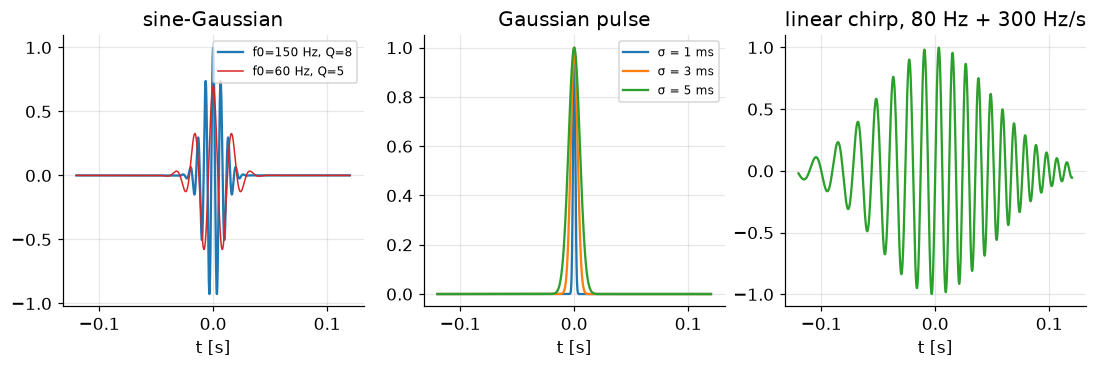

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
tt = np.linspace(-0.12, 0.12, 2000)
ax[0].plot(tt, np.exp(-tt**2 / (2 * (8/(2*np.pi*150))**2)) * np.cos(2*np.pi*150*tt), label="f0=150 Hz, Q=8", color=g.COLORS["freq"])
ax[0].plot(tt, 0.7*np.exp(-tt**2 / (2 * (5/(2*np.pi*60))**2)) * np.cos(2*np.pi*60*tt), label="f0=60 Hz, Q=5", color=g.COLORS["bayes"], lw=1)
ax[0].set_title("sine-Gaussian"); ax[0].legend(fontsize=8)
for s in (0.001, 0.003, 0.005): ax[1].plot(tt, np.exp(-tt**2 / (2*s**2)), label=f"σ = {s*1e3:.0f} ms")
ax[1].set_title("Gaussian pulse"); ax[1].legend(fontsize=8)
ax[2].plot(tt, np.exp(-tt**2 / (2*0.05**2)) * np.sin(2*np.pi*80*tt + np.pi*300*tt**2), color=g.COLORS["ml"])
ax[2].set_title("linear chirp, 80 Hz + 300 Hz/s")
for a in ax: a.set_xlabel("t [s]")
g.savefig(fig, "fig02_morphologies"); plt.show()

## 2. SNR: analytic against the time-domain proxy

For one noise-free injection we compare (i) the analytic optimal SNR from the PSD, (ii) the L2 norm of the whitened
waveform divided by the noise standard deviation, which is what the exploratory notebook did.

In [4]:
n = 4000
rows_proxy = []
for kind in g.MORPHS:
    p = g.draw_params(kind, rng, n)
    W = g.waveform_bins(kind, p, S1)                     # unit amplitude
    rho_true = g.snr_of(W)                               # analytic: 4 int |h|^2/S df  (in the band)
    wt = g.to_series(W)
    proxy = np.sqrt(np.sum(wt.astype(float)**2, axis=1)) / noise.std()
    rows_proxy.append(dict(morphology=kind, mean_ratio_proxy_over_analytic=float(np.mean(proxy / rho_true)),
                           std_ratio=float(np.std(proxy / rho_true))))
pd.DataFrame(rows_proxy)

,morphology,mean_ratio_proxy_over_analytic,std_ratio
0,sg,1.04953,6.944690e-09
1,pulse,1.04953,9.971361e-09
2,chirp,1.04953,2.805396e-09


With band-limited, unit-variance whitened noise the L2 proxy reproduces the analytic SNR to within the noise standard
deviation (0.95, i.e. a constant ≈5 % offset) — provided the signal is whitened with the *same* PSD. The analytic
definition has no such dependence and is the one used from now on: **all SNRs in the project are optimal SNRs**
$\rho=\sqrt{\langle h,h\rangle}$ with the PSD of the chunk the window belongs to.

## 3. Validation of the injection chain on real noise

If $d = n + h$ with Gaussian noise, the phase-maximised matched filter output with the exact template is
$|z|^2\sim\chi'^2_2(\lambda=\rho^2)$ (non-central, 2 degrees of freedom: the cosine and sine quadratures).

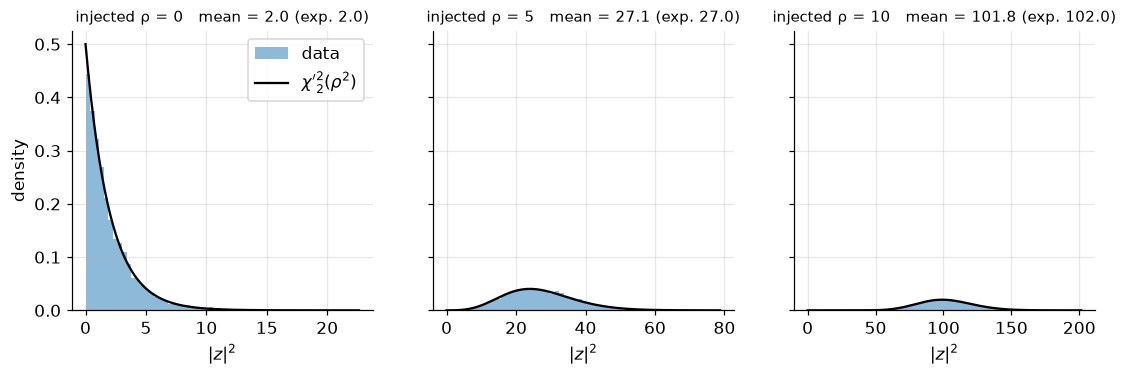

{'0.0': {'mean': 2.034985741039435,
  'expected': 2.0,
  'ks_p': 0.6401001800571362},
 '5.0': {'mean': 27.106239650988112,
  'expected': 27.0,
  'ks_p': 0.6630217224456905},
 '10.0': {'mean': 101.80868334051982,
  'expected': 102.0,
  'ks_p': 0.4887118190955084}}

In [5]:
def exact_template_stat(Xbins, p, S1):
    # phase-free complex template at the true (t0, f0, Q): positive-frequency part, unit norm
    T = 2 * g.sine_gaussian_ft(g.FREQ[None, :], p["f0"][:, None], p["Q"][:, None], 0.0, positive_only=True)
    T = T * np.exp(-2j*np.pi*g.FREQ[None, :]*p["t0"][:, None]) / np.sqrt(S1) * g.BAND
    T /= np.sqrt(np.sum(np.abs(T)**2, axis=1))[:, None]
    return np.abs(np.sum(Xbins * np.conj(T), axis=1)) ** 2

res = {}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for a, snr in zip(ax, (0.0, 5.0, 10.0)):
    idx = rng.choice(len(noise), 4000, replace=False)
    if snr > 0:
        series, p, _ = g.inject(noise[idx], "sg", snr, rng, S1)
    else:
        series, p = noise[idx], g.draw_params("sg", rng, len(idx))
    z2 = exact_template_stat(g.to_bins(series), p, S1)
    xs = np.linspace(0, z2.max(), 300)
    a.hist(z2, bins=60, density=True, color=g.COLORS["freq"], alpha=.5, label="data")
    a.plot(xs, stats.ncx2.pdf(xs, 2, snr**2), "k", label=r"$\chi'^2_2(\rho^2)$")
    ks = stats.kstest(z2, lambda x: stats.ncx2.cdf(x, 2, snr**2))
    a.set_title(f"injected ρ = {snr:g}   mean = {z2.mean():.1f} (exp. {2 + snr**2:.1f})", fontsize=10)
    a.set_xlabel(r"$|z|^2$"); res[str(snr)] = dict(mean=float(z2.mean()), expected=2 + snr**2, ks_p=float(ks.pvalue))
ax[0].legend(); ax[0].set_ylabel("density")
g.savefig(fig, "fig02_injection_validation"); plt.show(); res

The mean of $|z|^2$ is $2+\rho^2$ and the full distribution is non-central $\chi^2_2$: the amplitude calibration of the
injections and the noise model are consistent with each other. A KS p-value that is *not* uniformly large for the
noise-only case would signal the non-Gaussian tails seen in notebook 01; those are what the threshold calibration of
notebook 03 will have to absorb.

## 4. What an injection looks like

Whitened series (top) and spectrogram (bottom) for the same noise window and the same burst scaled to four SNR values.

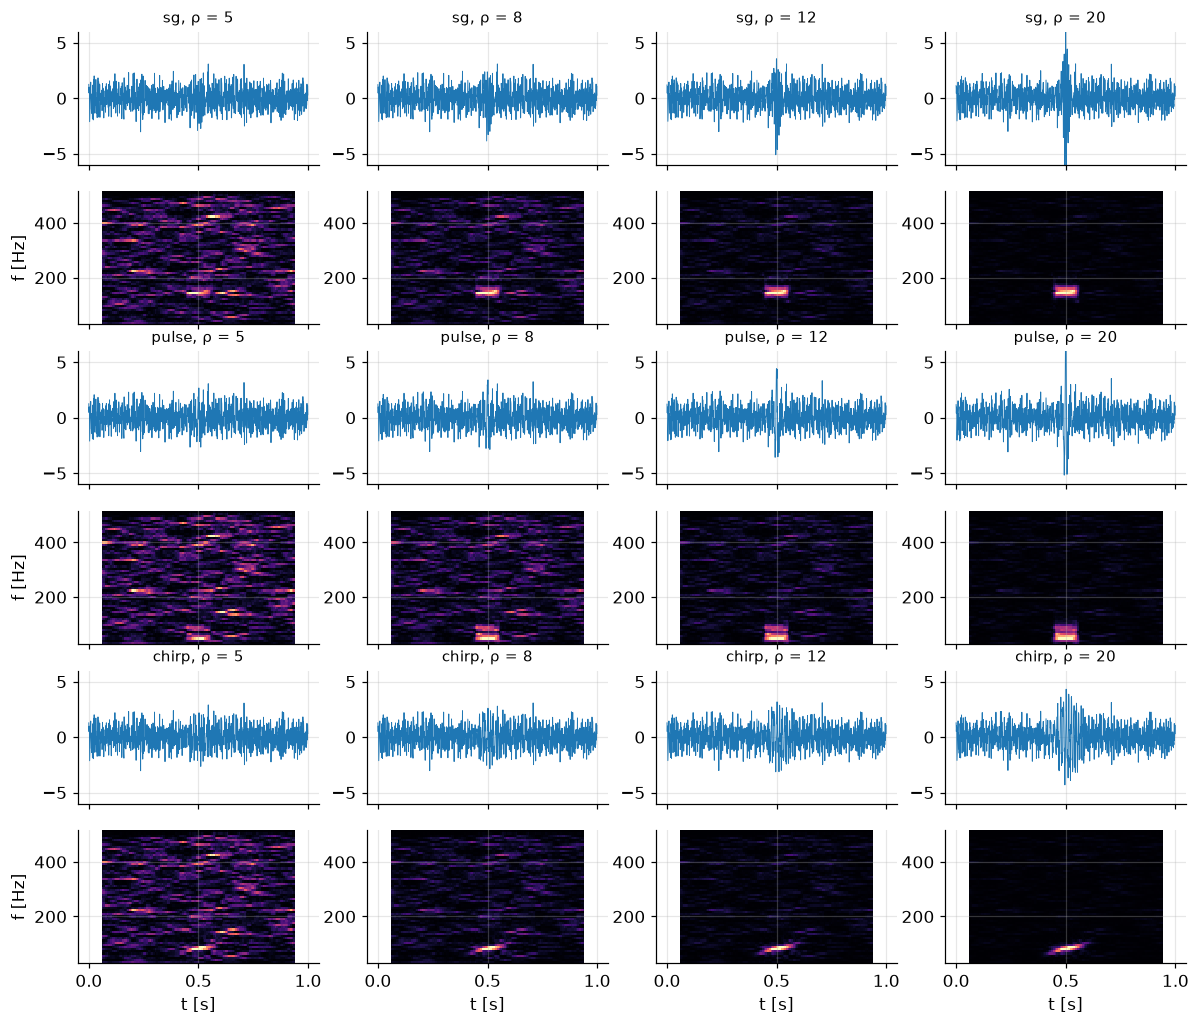

In [6]:
k = 777
params = {"sg":    dict(t0=np.array([.5]), phi=np.array([0.3]), f0=np.array([150.]), Q=np.array([8.])),
          "pulse": dict(t0=np.array([.5]), phi=np.array([0.]), sigma=np.array([0.003])),
          "chirp": dict(t0=np.array([.5]), phi=np.array([0.3]), f0=np.array([80.]), fdot=np.array([300.]), sigma=np.array([0.05]))}
snrs = (5, 8, 12, 20)
fig, ax = plt.subplots(2 * 3, 4, figsize=(13, 11), sharex=True)
for r, kind in enumerate(g.MORPHS):
    for c, snr in enumerate(snrs):
        s, _, _ = g.inject(noise[k:k+1], kind, snr, rng, S1, params=params[kind])
        a = ax[2*r, c]; a.plot(np.arange(g.NWIN)/g.FS, s[0], lw=.6, color=g.COLORS["H1"]); a.set_ylim(-6, 6)
        a.set_title(f"{kind}, ρ = {snr}", fontsize=10)
        ff, tt_, Sxx = signal.spectrogram(s[0], fs=g.FS, nperseg=128, noverlap=120)
        m = (ff > 25) & (ff < 520)
        ax[2*r+1, c].pcolormesh(tt_, ff[m], Sxx[m], shading="auto", cmap="magma", vmax=np.percentile(Sxx[m], 99.9))
for a in ax[-1]: a.set_xlabel("t [s]")
for a in ax[1::2, 0]: a.set_ylabel("f [Hz]")
g.savefig(fig, "fig02_injections_tf"); plt.show()

In [7]:
# peak amplitude of the whitened injection against the SNR (what a person would see in the time series)
rows = []
for kind in g.MORPHS:
    s, _, snr = g.inject(np.zeros((1000, g.NWIN), np.float32), kind, 10.0, rng, S1)
    rows.append(dict(morphology=kind, mean_peak_per_unit_snr=float(np.mean(np.max(np.abs(s), axis=1)) / 10)))
pd.DataFrame(rows)

,morphology,mean_peak_per_unit_snr
0,sg,0.327545
1,pulse,0.503825
2,chirp,0.148030


At ρ ≈ 5 the burst is invisible by eye in all three morphologies, at ρ ≈ 8–12 the sine-Gaussian and the chirp appear in the
spectrogram, while the very short Gaussian pulse (broadband, a few ms) shows up as a vertical line only at ρ ≳ 12. The
energy of each morphology spreads over a different number of time–frequency pixels, which is the origin of the
different detection efficiencies measured in notebooks 03–05.

## Output and next step

* `results/02_summary.json` — injection-chain validation numbers; `figures/fig02_*`.
* Library functions used downstream: `inject`, `draw_params`, `waveform_bins`, `snr_of`.

Next: **`03_frequentist_analysis.ipynb`** — matched-filter bank, profile likelihood, background calibration, toy MC.

In [8]:
g.save_json({"injection_validation": res, "proxy_vs_analytic": rows_proxy, "peak_per_unit_snr": rows}, "02_summary.json")